This notebook will combine the song/chart data with the NLP features and create a clean, modeling-ready feature dataset.

The most important improvement here is that we will explicity separate:

1) Features available for prediction
2) Outcome/target variables
3) Descriptive lifetime performance variables 

The prevents the leakage problem we discussed earlier.

Project flow

Cleaned Spotify Dataset
|
Lyrics NLP Featires
|
Notebook 07
|
Feature Engineering
|
Feature Validation
|
Prediction Targets
|
Modeling Datasets
|
Notebook 08- Hit Segmentation
|
Notebook 09 - Machine LEarning


### Spotify Global Hit Intelligence

This notebook combines song-level chart information with lyrics-derived NLP features and creates a structured feature set for downstream segmentation and machine learning.

#### Objectives

1. Load the cleaned Spotify dataset
2. Load the lyrics NLP feature dataset
3. Validate the merge
4. Create song-level engineered features
5. Create lyric-derived features
6. Create performance descriptors
7. Apply appropriate transformations
8. Define prediction targets.
9. Separate predictors from outcome variables
10. Create modeling-ready datasets
11. Validate the final feature set

#### Important Modeling Principle

Lifetime chart outcomes such as:

- total streams
- weeks on chart
- Top-10 weeks
- peak streams

are outcomes of a song's complete chart history.

They should not be used a predictors when the objective is to predict future chart success.

Therefore this notebook explicitly separates:

#### Predictive Features

Information that can reasonably be available before or independently of the final chart outcome.

#### Outcome Variables

Measures of the song's eventual chart performance.

This separation helps prevent target leakage.

In [1]:
# Import Libraries

import warnings
from pathlib import Path 

import numpy as np 
import pandas as pd 

import matplotlib.pyplot as plt 
import seaborn as sns 

from IPython.display import display 

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")


pandas= feature engineering
numpy - mathematical transformations
matplotlib/seaborn - feature distributions
Path - reliable file management 

In [2]:
# Define Project Paths - Use the absolute project path 

PROJECT_ROOT = Path(
    r"C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence"
)

CLEAN_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_global_chart_totals_lyrics_cleaned.csv"
)

NLP_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_lyrics_nlp_features.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "feature_engineering"
)

TABLE_DIR = (
    PROJECT_ROOT 
    / "outputs"
    / "tables"
    / "feature_engineering"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root:")
print(PROJECT_ROOT)

print("\nClean dataset:")
print(CLEAN_DATA_PATH)

print("\nNLP dataset:")
print(NLP_DATA_PATH)

Project root:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence

Clean dataset:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_global_chart_totals_lyrics_cleaned.csv

NLP dataset:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_lyrics_nlp_features.csv


In [3]:
# Verify Input Files

print(
    "Clean dataset exists:",
    CLEAN_DATA_PATH.exists()
)

print(
    "NLP Feature dataset exists:",
    NLP_DATA_PATH.exists()
)


Clean dataset exists: True
NLP Feature dataset exists: True


In [4]:
# Load the Cleaned dataset 

df = pd.read_csv(
    CLEAN_DATA_PATH,
    low_memory=False
)

print(
    "Clean dataset shape:",
    df.shape 
)

display(df.head())

Clean dataset shape: (8058, 29)


,artist and title,wks,t10,pk,PkStreams,total,artist name,song name,lyrics,peak_duration,artist_song_key,artist_song_key_normalized,wks_outlier,t10_outlier,PkStreams_outlier,total_outlier,extreme_performance_count,log_total,log_wks,log_PkStreams,log_t10,lyrics_original,lyrics_available,lyrics_clean,lyrics_char_count,lyrics_word_count,lyrics_line_count,words_per_line,top10_reached
0,The Weeknd - Blinding Lights,347,64,1,52375259,5441240333,The Weeknd,Blinding Lights,Yeah I've been tryna call I've been on my own ...,13.0,The Weeknd | Blinding Lights,the weeknd | blinding lights,True,True,True,True,4,22.417273,5.852202,17.773945,4.174387,Yeah I've been tryna call I've been on my own ...,True,Yeah I've been tryna call I've been on my own ...,1230,259,1,259.0,1
1,Ed Sheeran - Shape of You,424,34,1,64217796,4470842634,Ed Sheeran,Shape of You,The club isn't the best place to find a lover ...,14.0,Ed Sheeran | Shape of You,ed sheeran | shape of you,True,True,True,True,4,22.220843,6.052089,17.977791,3.555348,The club isn't the best place to find a lover ...,True,The club isn't the best place to find a lover ...,3139,688,1,688.0,1
2,Harry Styles - As It Was,218,60,1,78460903,4417264164,Harry Styles,As It Was,﻿ As It Was - Harry Styles Come on Harry we wa...,11.0,Harry Styles | As It Was,harry styles | as it was,True,True,True,True,4,22.208786,5.389072,18.178111,4.110874,﻿ As It Was - Harry Styles Come on Harry we wa...,True,﻿ As It Was - Harry Styles Come on Harry we wa...,1143,243,1,243.0,1
3,The Neighbourhood - Sweater Weather,333,0,16,21624450,4142643719,The Neighbourhood,Sweater Weather,And all I am is a man I want the world in my h...,NaN,The Neighbourhood | Sweater Weather,the neighbourhood | sweater weather,True,False,False,True,2,22.144600,5.811141,16.889335,NaN,And all I am is a man I want the world in my h...,True,And all I am is a man I want the world in my h...,1678,345,1,345.0,0
4,Lewis Capaldi - Someone You Loved,343,15,4,24962682,3933581891,Lewis Capaldi,Someone You Loved,I'm going under and this time I fear there's n...,NaN,Lewis Capaldi | Someone You Loved,lewis capaldi | someone you loved,True,False,False,True,2,22.092816,5.840642,17.032893,2.772589,I'm going under and this time I fear there's n...,True,I'm going under and this time I fear there's n...,1555,323,1,323.0,1


In [5]:
# Load NLP Features

nlp_features = pd.read_csv(
        NLP_DATA_PATH,
        low_memory=False 
)

print(
    "NLP feature dataset shape",
    nlp_features.shape 
)

display(nlp_features.head())

NLP feature dataset shape (8058, 15)


,artist name,song name,lyrics_available,lyrics_char_count,lyrics_word_count,lyrics_unique_word_count,meaningful_word_count,lexical_diversity,avg_word_length,sentiment_polarity,sentiment_subjectivity,sentiment_category,dominant_topic,topic_probability,lyric_complexity_group
0,The Weeknd,Blinding Lights,True,1089,235,92,99,0.391489,3.638298,0.037500,0.597222,Negative,5,0.679882,Middle lexical diversity
1,Ed Sheeran,Shape of You,True,2940,669,144,282,0.215247,3.396114,0.299260,0.493270,Positive,2,0.811826,Lower lexical diversity
2,Harry Styles,As It Was,True,1115,245,97,82,0.395918,3.555102,0.078571,0.250595,Positive,5,0.735412,Middle lexical diversity
3,The Neighbourhood,Sweater Weather,True,1655,346,134,155,0.387283,3.786127,-0.100366,0.656995,Neutral,5,0.763539,Middle lexical diversity
4,Lewis Capaldi,Someone You Loved,True,1543,323,95,132,0.294118,3.780186,0.267677,0.541414,Positive,5,0.991246,Middle lexical diversity


In [6]:
# Inspect NLP columns

print("NLP feature columns:")

for i, col in enumerate(
    nlp_features.columns,
    start=1
):
    print(f"{i}. {col}")

NLP feature columns:
1. artist name
2. song name
3. lyrics_available
4. lyrics_char_count
5. lyrics_word_count
6. lyrics_unique_word_count
7. meaningful_word_count
8. lexical_diversity
9. avg_word_length
10. sentiment_polarity
11. sentiment_subjectivity
12. sentiment_category
13. dominant_topic
14. topic_probability
15. lyric_complexity_group


8. Validate Song Keys before Merging 

We will use artist name + song name as the merge key.

In [7]:
df["artist_song_key"] = (
    df["artist name"].astype("string").str.strip()
    + " | "
    + df["song name"].astype("string").str.strip()
)

nlp_features["artist_song_key"] = (
    nlp_features["artist name"].astype("string").str.strip()
    + " | "
    + nlp_features["song name"].astype("string").str.strip()
)

In [8]:
# 9 . Check Duplicate Keys

print(
    "Duplicate keys in cleaned dataset:",
    df["artist_song_key"].duplicated().sum()
)

print(
    "Duplicate keys in NLP dataset:",
    nlp_features["artist_song_key"].duplicated().sum()
)

Duplicate keys in cleaned dataset: 233
Duplicate keys in NLP dataset: 233


Earlier analysis showed that the dataset contains repeated artist-song combinations.

Therefore, we must not blindly assume that the key is unique

In [9]:
# Lets inspect them

duplicate_nlp_keys = (
    nlp_features[
        nlp_features["artist_song_key"].duplicated(
            keep=False
        )
    ]
    .sort_values("artist_song_key")
)

display(
    duplicate_nlp_keys.head(20)
)

,artist name,song name,lyrics_available,lyrics_char_count,lyrics_word_count,lyrics_unique_word_count,meaningful_word_count,lexical_diversity,avg_word_length,sentiment_polarity,sentiment_subjectivity,sentiment_category,dominant_topic,topic_probability,lyric_complexity_group,artist_song_key
3024,4batz,act ii: date @ 8,True,907,193,72,93,0.373057,3.704663,0.028241,0.602315,Negative,6,0.934837,Middle lexical diversity,4batz | act ii: date @ 8
4227,4batz,act ii: date @ 8,True,907,193,72,93,0.373057,3.704663,0.028241,0.602315,Negative,6,0.934837,Middle lexical diversity,4batz | act ii: date @ 8
2627,A Great Big World,Say Something,True,705,143,54,56,0.377622,3.937063,-0.042857,0.542857,Negative,5,0.934447,Middle lexical diversity,A Great Big World | Say Something
3042,A Great Big World,Say Something,True,705,143,54,56,0.377622,3.937063,-0.042857,0.542857,Negative,5,0.934447,Middle lexical diversity,A Great Big World | Say Something
5086,AFROJACK,SummerThing!,True,1582,341,71,140,0.208211,3.642229,0.151786,0.700000,Positive,5,0.694724,Lower lexical diversity,AFROJACK | SummerThing!
8007,AFROJACK,SummerThing!,True,1582,341,71,140,0.208211,3.642229,0.151786,0.700000,Positive,5,0.694724,Lower lexical diversity,AFROJACK | SummerThing!
2865,ANOTR,Talk To You,True,902,209,43,92,0.205742,3.320574,0.296875,0.543750,Positive,2,0.862451,Lower lexical diversity,ANOTR | Talk To You
4793,ANOTR,Talk To You,True,902,209,43,92,0.205742,3.320574,0.296875,0.543750,Positive,2,0.862451,Lower lexical diversity,ANOTR | Talk To You
1504,Alesso,Heroes,True,1050,224,70,97,0.312500,3.691964,0.110248,0.598137,Positive,5,0.987307,Middle lexical diversity,Alesso | Heroes
4847,Alesso,Heroes,True,1050,224,70,97,0.312500,3.691964,0.110248,0.598137,Positive,5,0.987307,Middle lexical diversity,Alesso | Heroes


If the NLP file contains one row per original record, the safest merge is based on the original row identity rather than aggregating songs.

Because both datasets originated from the same 8,058 records, we can use an index-based validation approcah.

In [10]:
# 10 . Add Original ROW ID 
# if the datasets have exactly same ordering, we can create a stable row or identifier

df["record_id"] = np.arange(
    len(df)
)

nlp_features["record_id"] = np.arange(
    len(nlp_features)
)

In [11]:
# Validate

print(
    "Same number of records:",
    len(df) == len(nlp_features)
)


print(
    "Record IDs match:",
    df["record_id"].equals(
        nlp_features["record_id"]
    )
)

Same number of records: True
Record IDs match: True


In [12]:
# 11. Validate Artist and Song Alignment 

alignment_check = (
    df["artist name"].astype("string").fillna("")
    .equals(
        nlp_features["artist name"] 
        .astype("string")
        .fillna("")
    )
    and
    df["song name"].astype("string").fillna("")
    .equals(
        nlp_features["song name"]
        .astype("string").fillna("")
    )
)

print(
    "Artist/song alignment:",
    alignment_check
)

Artist/song alignment: True


In [13]:
# Combine Datasets - Since the record IDs match,merge using record_id

nlp_columns_to_add = [
    "record_id",
    "lyrics_available",
    "lyrics_char_count",
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "meaningful_word_count",
    "lexical_diversity",
    "avg_word_length",
    "sentiment_polarity",
    "sentiment_subjectivity",
    "sentiment_category",
    "dominant_topic",
    "topic_probability",
    "lyric_complexity_group"
] 


feature_df = df.merge(
    nlp_features[nlp_columns_to_add],
    on="record_id",
    how="left",
    validate="one_to_one"
)

print(
    "Combined dataset shape:",
    feature_df.shape
)

Combined dataset shape: (8058, 43)


Why validate = "one_to_one"?

It protects us from accidentally creating duplicate rows during the merge. If the merge unexpectedly becomes 8058 + 12,000 rows

the code will fail instead of silently corrupting the dataset.

In [14]:
# 13. Validate Merge

print(
    "Original rows:",
    len(df)
)

print(
    "Combined rows:",
    len(feature_df)
)

print(
    "Rows preserved:",
    len(df) == len(feature_df)
)

Original rows: 8058
Combined rows: 8058
Rows preserved: True


In [15]:
# 14. Remove Temporary Merge Keys - We don't need the keys for modeling.

feature_df = feature_df.drop(
    columns= [
        "record_id",
        "artist_song_key"
    ],
    errors="ignore"
)

print(
    "Feature dataframe shape:",
    feature_df.shape
)

Feature dataframe shape: (8058, 41)


In [16]:
# Inspect Data types

feature_df.dtypes

artist and title                  str
wks                             int64
t10                             int64
pk                              int64
PkStreams                       int64
total                           int64
artist name                       str
song name                         str
lyrics                            str
peak_duration                 float64
artist_song_key_normalized        str
wks_outlier                      bool
t10_outlier                      bool
PkStreams_outlier                bool
total_outlier                    bool
extreme_performance_count       int64
log_total                     float64
log_wks                       float64
log_PkStreams                 float64
log_t10                       float64
lyrics_original                   str
lyrics_available_x               bool
lyrics_clean                      str
lyrics_char_count_x             int64
lyrics_word_count_x             int64
lyrics_line_count               int64
words_per_li

This helps identify: numerical features, categorical features, text fields & Boolean fields

In [17]:
# 16. Create Basic Song-Level features - Now we'll create features that describe the song's chart performance.

feature_df["peak_position_score"] = (
    247 - feature_df["pk"]
) / 246

pk represents peak chart position, Lower is better pk=1 meangs the song reached # 1. Instead of using the inverse directly, we transform it into a normalized score: # 1 -> close to 1 # 246 -> clode to 0 This is a descriptive transformation.

In [18]:
# 17. Create Top-10 Rate

feature_df["top10_week_ratio"] = (
    feature_df["t10"]
    /
    feature_df["wks"].replace(
        0,
        np.nan
    )
)

This measures: Top-10 weeks / Total chart weeks

Example: 20 chart weeks & 5 Top-10 weeks
gives 5 / 20 = 0.25

so 25% of the song's chart life was spent in the Top 10 

Important: This is a lifetime outcome descriptor. Do not use it as a predictor when forecasting future performance.

In [19]:
# 18. Create Peak Stream Share

feature_df["peak_stream_share"] = (
    feature_df["PkStreams"]
    /
    feature_df["total"].replace(
        0,
        np.nan
    )
)

This measures the relationship between peak weekly streams and lifetime streams.

Again, it is a descriptive performance feature, not a safe pre-outcome predictor.

In [20]:
# 19. Create Streams per Chart Week

feature_df["streams_per_week"] = (
    feature_df["total"]
    /
    feature_df["wks"].replace(
        0,
        np.nan 
    )
)

This tells us the average number of streams accumulated per chart week.

In [21]:
# 20. Create Peak Streams per Week

feature_df["peak_streams_per_week"] = (
    feature_df["PkStreams"]
    /
    feature_df["wks"].replace(
        0,
        np.nan 
    )
)

This is another descriptive intensity measure.

In [22]:
# 21. Create Log-Transformed Performance Features

# Because streaming variables are extremely right-skewed, log transformations are useful.

for col in [
    "total",
    "PkStreams",
    "wks",
    "streams_per_week",
    "peak_streams_per_week"
]:

    feature_df[f"log_{col}"] = np.log1p(
        feature_df[col]
    )

For example: total = 5,441,240,333 is extremely large compared with the median.

Using np.log1p(total) compresses the extreme values.

This often makes numerical relationships easier for ML algorithms to model.

In [23]:
# 22. Create Lyrics-Derived Features 

feature_df["lyric_repetition_ratio"] = (
    1 
    - feature_df["lexical_diversity"]
)

If: lexical diversity = 0.70 then: repetition ratio = 0.30 
Higher values indicate more repeated vocabulary relative to total vocabulary.

This is an engineered feature derived from the NLP output.

In [24]:
print(nlp_features.columns.tolist())

['artist name', 'song name', 'lyrics_available', 'lyrics_char_count', 'lyrics_word_count', 'lyrics_unique_word_count', 'meaningful_word_count', 'lexical_diversity', 'avg_word_length', 'sentiment_polarity', 'sentiment_subjectivity', 'sentiment_category', 'dominant_topic', 'topic_probability', 'lyric_complexity_group', 'artist_song_key', 'record_id']


Create a stable record ID 
Because the original dataset contains some repeated artist-song combinations, don't use artist + song as the merge key

Instead, both files came from the same 8,058 row dataset, so use the original row order.

In [25]:
df["record_id"] = np.arange(len(df))

nlp_features["record_id"] = np.arange(
    len(nlp_features)
)

print(
    "Clean IDs:",
    df["record_id"].head().tolist()
)

print(
    "NLP IDs:",
    nlp_features["record_id"].head().tolist()
)

Clean IDs: [0, 1, 2, 3, 4]
NLP IDs: [0, 1, 2, 3, 4]


In [26]:
# Verify that the two files are aligned

artist_match = (
    df["artist name"]
    .astype("string")
    .fillna("")
    .equals(
        nlp_features["artist name"]
        .astype("string")
        .fillna("")
    )
)

song_match = (
    df["song name"]
    .astype("string")
    .fillna("")
    .equals(
        nlp_features["song name"]
        .astype("string")
        .fillna("")
    )
)


print("Artist alignment:", artist_match)
print("Song alignment:", song_match)

Artist alignment: True
Song alignment: True


In [27]:
# Merge the NLP features

nlp_columns_to_add = [
    "record_id",
    "lyrics_available",
    "lyrics_char_count",
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "meaningful_word_count",
    "lexical_diversity",
    "avg_word_length",
    "sentiment_polarity",
    "sentiment_subjectivity",
    "sentiment_category",
    "dominant_topic",
    "topic_probability",
    "lyric_complexity_group"
]

feature_df = df.merge(
    nlp_features[nlp_columns_to_add],
    on="record_id",
    how="left",
    validate="one_to_one"
)

print(
    "Feature dataframe shape:",
    feature_df.shape
)

Feature dataframe shape: (8058, 43)


In [28]:
# ============================================================
# REBUILD FEATURE DATAFRAME FROM SOURCE FILES
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence"
)

CLEAN_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_global_chart_totals_lyrics_cleaned.csv"
)

NLP_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_lyrics_nlp_features.csv"
)

# Load fresh copies
df = pd.read_csv(CLEAN_DATA_PATH, low_memory=False)
nlp_features = pd.read_csv(NLP_DATA_PATH, low_memory=False)

print("Main dataset:", df.shape)
print("NLP dataset:", nlp_features.shape)

# ------------------------------------------------------------
# Create a stable row ID based on original row order
# ------------------------------------------------------------

df["record_id"] = np.arange(len(df))
nlp_features["record_id"] = np.arange(len(nlp_features))

# ------------------------------------------------------------
# Validate row alignment before combining
# ------------------------------------------------------------

artist_match = (
    df["artist name"].astype("string").fillna("")
    .equals(
        nlp_features["artist name"].astype("string").fillna("")
    )
)

song_match = (
    df["song name"].astype("string").fillna("")
    .equals(
        nlp_features["song name"].astype("string").fillna("")
    )
)

print("Artist alignment:", artist_match)
print("Song alignment:", song_match)

# ------------------------------------------------------------
# NLP columns required for Feature Engineering
# ------------------------------------------------------------

nlp_columns = [
    "lyrics_available",
    "lyrics_char_count",
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "meaningful_word_count",
    "lexical_diversity",
    "avg_word_length",
    "sentiment_polarity",
    "sentiment_subjectivity",
    "sentiment_category",
    "dominant_topic",
    "topic_probability",
    "lyric_complexity_group"
]

# Check that source NLP file actually contains them
missing_from_nlp = [
    col for col in nlp_columns
    if col not in nlp_features.columns
]

print("Missing from NLP source:")
print(missing_from_nlp)

# ------------------------------------------------------------
# Combine using row ID
# concat is safer here because alignment was already validated
# ------------------------------------------------------------

feature_df = pd.concat(
    [
        df.reset_index(drop=True),
        nlp_features[nlp_columns].reset_index(drop=True)
    ],
    axis=1
)

print("\nFeature dataframe shape:", feature_df.shape)

Main dataset: (8058, 29)
NLP dataset: (8058, 15)
Artist alignment: True
Song alignment: True
Missing from NLP source:
[]

Feature dataframe shape: (8058, 43)


In [29]:
# Check the required columns

required_nlp_columns = [
    "lyrics_available",
    "lyrics_char_count",
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "meaningful_word_count",
    "lexical_diversity",
    "avg_word_length",
    "sentiment_polarity",
    "sentiment_subjectivity",
    "sentiment_category",
    "dominant_topic",
    "topic_probability",
    "lyric_complexity_group"
]

missing_nlp = [
    col for col in required_nlp_columns
    if col not in feature_df.columns
]

print("Missing NLP columns:")
print(missing_nlp)

Missing NLP columns:
[]


In [30]:
print(
    feature_df[
        [
            "lyrics_available",
            "lyrics_char_count",
            "lyrics_word_count"
        ]
    ].head()
)

   lyrics_available  lyrics_available  lyrics_char_count  lyrics_char_count  \
0              True              True               1230               1089   
1              True              True               3139               2940   
2              True              True               1143               1115   
3              True              True               1678               1655   
4              True              True               1555               1543   

   lyrics_word_count  lyrics_word_count  
0                259                235  
1                688                669  
2                243                245  
3                345                346  
4                323                323  


In [31]:
# Verify the missing column

print(
    "lyrics_word_count exists:",
    "lyrics_word_count" in feature_df.columns
)

print(
    "lyrics_unique_word_count exists:",
    "lyrics_unique_word_count" in feature_df.columns
)

print(
    "lexical_diversity exists:",
    "lexical_diversity" in feature_df.columns
)

lyrics_word_count exists: True
lyrics_unique_word_count exists: True
lexical_diversity exists: True


In [32]:
print(nlp_features.columns.tolist())

['artist name', 'song name', 'lyrics_available', 'lyrics_char_count', 'lyrics_word_count', 'lyrics_unique_word_count', 'meaningful_word_count', 'lexical_diversity', 'avg_word_length', 'sentiment_polarity', 'sentiment_subjectivity', 'sentiment_category', 'dominant_topic', 'topic_probability', 'lyric_complexity_group', 'record_id']


In [33]:
display(
    feature_df[
        [
            "artist name",
            "song name",
            "lyrics_word_count",
            "lyrics_unique_word_count",
            "lexical_diversity",
            "sentiment_polarity",
            "dominant_topic"
        ]
    ].head(10)
)

,artist name,song name,lyrics_word_count,lyrics_word_count,lyrics_unique_word_count,lexical_diversity,sentiment_polarity,dominant_topic
0,The Weeknd,Blinding Lights,259,235,92,0.391489,0.037500,5
1,Ed Sheeran,Shape of You,688,669,144,0.215247,0.299260,2
2,Harry Styles,As It Was,243,245,97,0.395918,0.078571,5
3,The Neighbourhood,Sweater Weather,345,346,134,0.387283,-0.100366,5
4,Lewis Capaldi,Someone You Loved,323,323,95,0.294118,0.267677,5
5,The Weeknd,Starboy,451,449,166,0.369710,0.131546,6
6,Billie Eilish,BIRDS OF A FEATHER,293,274,112,0.408759,0.216667,5
7,Lady Gaga,Die With A Smile,293,293,84,0.286689,0.113805,5
8,Post Malone,Sunflower,298,292,126,0.431507,-0.125548,5
9,Ed Sheeran,Perfect,289,286,129,0.451049,0.439596,5


In [34]:
# ============================================================
# FINAL CLEAN REBUILD OF feature_df
# ============================================================

import pandas as pd
import numpy as np

# Reload source datasets
df = pd.read_csv(
    CLEAN_DATA_PATH,
    low_memory=False
)

nlp_features = pd.read_csv(
    NLP_DATA_PATH,
    low_memory=False
)

# Reset indexes
df = df.reset_index(drop=True)
nlp_features = nlp_features.reset_index(drop=True)

# ------------------------------------------------------------
# Validate row count
# ------------------------------------------------------------

print("Main dataset:", df.shape)
print("NLP dataset:", nlp_features.shape)

assert len(df) == len(nlp_features), (
    "Row counts do not match!"
)

# ------------------------------------------------------------
# Validate artist/song alignment
# ------------------------------------------------------------

artist_match = (
    df["artist name"].astype("string").fillna("").equals(
        nlp_features["artist name"].astype("string").fillna("")
    )
)

song_match = (
    df["song name"].astype("string").fillna("").equals(
        nlp_features["song name"].astype("string").fillna("")
    )
)

print("Artist alignment:", artist_match)
print("Song alignment:", song_match)

assert artist_match, "Artist rows are not aligned!"
assert song_match, "Song rows are not aligned!"

# ------------------------------------------------------------
# NLP columns
# ------------------------------------------------------------

nlp_columns = [
    "lyrics_available",
    "lyrics_char_count",
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "meaningful_word_count",
    "lexical_diversity",
    "avg_word_length",
    "sentiment_polarity",
    "sentiment_subjectivity",
    "sentiment_category",
    "dominant_topic",
    "topic_probability",
    "lyric_complexity_group"
]

# Verify source
missing_source_columns = [
    col for col in nlp_columns
    if col not in nlp_features.columns
]

print("Missing from NLP source:", missing_source_columns)

assert not missing_source_columns, (
    "NLP source file is missing required columns."
)

# ------------------------------------------------------------
# IMPORTANT:
# Remove any NLP columns already existing in df
# before concatenating them.
# ------------------------------------------------------------

existing_nlp_columns = [
    col for col in nlp_columns
    if col in df.columns
]

print("NLP columns already in main dataframe:")
print(existing_nlp_columns)

df_base = df.drop(
    columns=existing_nlp_columns,
    errors="ignore"
).copy()

# ------------------------------------------------------------
# Concatenate
# ------------------------------------------------------------

feature_df = pd.concat(
    [
        df_base,
        nlp_features[nlp_columns]
    ],
    axis=1
)

# ------------------------------------------------------------
# Final duplicate-column check
# ------------------------------------------------------------

duplicate_columns = feature_df.columns[
    feature_df.columns.duplicated()
].tolist()

print("\nFeature dataframe:", feature_df.shape)
print("Duplicate columns:", duplicate_columns)

assert len(duplicate_columns) == 0, (
    f"Duplicate columns remain: {duplicate_columns}"
)

print("\nFeature dataframe rebuilt successfully!")

Main dataset: (8058, 29)
NLP dataset: (8058, 15)
Artist alignment: True
Song alignment: True
Missing from NLP source: []
NLP columns already in main dataframe:
['lyrics_available', 'lyrics_char_count', 'lyrics_word_count']

Feature dataframe: (8058, 39)
Duplicate columns: []

Feature dataframe rebuilt successfully!


In [35]:
# 23. Unique Word Ratio

feature_df["unique_word_ratio"] = (
    feature_df["lyrics_unique_word_count"]
    /
    feature_df["lyrics_word_count"].replace(0, np.nan)
)

print(
    feature_df["unique_word_ratio"].describe()
)

count    8025.000000
mean        0.358164
std         0.100911
min         0.016667
25%         0.292818
50%         0.353175
75%         0.417208
max         1.000000
Name: unique_word_ratio, dtype: float64


This should be very close to lexical diversity.

We keep both concepts for clarity, but later we should avoid redundant features if they are mathematically identical

In [36]:
# Verify

print(
    np.allclose(
        feature_df["unique_word_ratio"].fillna(0),
        feature_df["lexical_diversity"].fillna(0)

    )
)

True


In [37]:
# 24. Lyric Length Category

feature_df["lyric_length_group"] = pd.qcut(
    feature_df["lyrics_word_count"],
    q=4,
    labels=[
        "Short",
        "Medium",
        "Long",
        "Very Long"
    ],
    duplicates="drop"
)

We divide songs into four groups based on their word counts

This is preferable to arbitrary rules such as:
<200 = short & >500 = long

because the quartiles are derived from the dataset.

In [38]:
# 25. Sentiment Intensity 

feature_df["sentiment_intensity"] = (
    feature_df["sentiment_polarity"].abs()
)

Polarity  measures direction -0.8 -> negative & 0.8 -> positive 

Intensity ignores direction -> -0.8 & 0.8 -> both 0.8

This lets us investigate whether strongly polarized lyrics differ from lyrics closer to neutral.

In [39]:
# 26. Sentiment Direction

feature_df["sentiment_direction"] = np.select(
    [
        feature_df["sentiment_polarity"] > 0.05,
        feature_df["sentiment_polarity"] < -0.05
    ],
    [
        "Positive",
        "Negative"
    ],
    default = "Neutral"
)

This duplicates some information from sentiment_category, so later we will keep only one categorical representation for modeling.

In [40]:
# 27. Topic Confidence Groups

feature_df["topic_confidence_group"] = pd.cut(
    feature_df["topic_probability"],
    bins=[
        -np.inf,
        0.40,
        0.60,
        0.80,
        np.inf
    ],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Very High"
    ]
)

A song may not belong strongly to one topic.

For example:
Topic 1 = 0.26
Topic 2 = 0.27
Topic 3 = 0.25
Topic 4 = 0.22

has low topic concentration.

Another song:

Topic 1 = 0.91 has a much clearer dominant topic.




### 28. Create Outcome Variables - Now we need to explicitly define what we are trying to predict.

This is critical. We will create two possible targets

In [41]:
# Target A - High Total Streams

# We'll define a high-stream song as being in the Top 25% of lifetime total streams.

total_stream_threshold = (
    feature_df["total"].quantile(0.75)
)

feature_df["high_total_streams"] = (
    feature_df["total"]
    >= total_stream_threshold
).astype(int)

print(
    "75th percentile total streams:",
    total_stream_threshold
)

print(
    "\nTarget Distribution"
)

display(
    feature_df[
        "high_total_streams"
    ].value_counts()
)

75th percentile total streams: 118804261.75

Target Distribution


high_total_streams
0    6043
1    2015
Name: count, dtype: int64

This creates 0 -> below top 25% & 1 -> top 25%

This is useful for classification 

Critical point: total is the target, not a predictor.

In [42]:
# 29. Target B - Long-Running Song

longevity_threshold = (
    feature_df["wks"].quantile(0.75)
)

feature_df["long_running_song"] = (
    feature_df["wks"]
    >= longevity_threshold
).astype(int)

print(
    "75th percentile weeks:",
    longevity_threshold
)

display(
    feature_df[
        "long_running_song"
    ].value_counts()
)

75th percentile weeks: 17.0


long_running_song
0    6007
1    2051
Name: count, dtype: int64

This creates 0 -> below the 75th percentile of chart longevity
1 -> long-running song

This will give us another classification target.

In [43]:
# 30. Top-10 Target

# we already have top10_reached we can use it as a separate outcome.

print(
    feature_df[
        "top10_reached"
    ].value_counts()
)

print(
    "\nTop-10 percentage:"
)

print(
    feature_df[
        "top10_reached"
    ].mean() * 100
)

top10_reached
0    7248
1     810
Name: count, dtype: int64

Top-10 percentage:
10.052122114668652


Important leakage warning: For a predictive model:

top10_reached is the target. Therefore we cannot use t10, t10_week_ratio as predictors.

In [44]:
# 31. Define Outcome Columns

OUTCOME_COLUMNS = [
    "total",
    "wks",
    "t10",
    "PkStreams",
    "pk",
    "top10_reached",
    "high_total_streams",
    "long_running_song"
]

print("Outcome variables:")

for col in OUTCOME_COLUMNS:
    print("-", col)

Outcome variables:
- total
- wks
- t10
- PkStreams
- pk
- top10_reached
- high_total_streams
- long_running_song


In [45]:
# 32. Define Safe Predictive Features 
# For our initial content-based modeling, we will use the NLP features.

SAFE_NLP_FEATURES = [
    "lyrics_available",
    "lyrics_char_count",
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "meaningful_word_count",
    "lexical_diversity",
    "avg_word_length",
    "sentiment_polarity",
    "sentiment_subjectivity",
    "sentiment_intensity",
]

print(
    "Number of safe NLP features:",
    len(SAFE_NLP_FEATURES)
)

Number of safe NLP features: 10


Why are these safe?

They describe the lyrics. The lyrics are conceptually available independently of the song's eventual lifetime chart performance.

Therefore we can use:

Lyrics
|
NLP features
|
Predict future chart outcome.

This is much more defensible than using final chart metrics to predict final chart metrics.

In [46]:
# 33. Remove Redundant Feature 
# unique_word_ratio and lexical_diversity represent essentially the same calculation. We'll keep lexical_diversity

MODELING_NLP_FEATURES = [
    col 
    for col in SAFE_NLP_FEATURES
    if col != "unique_word_ratio"
]

print(
    "Modeling NLP features:"
)

for col in MODELING_NLP_FEATURES:
    print("-", col)

Modeling NLP features:
- lyrics_available
- lyrics_char_count
- lyrics_word_count
- lyrics_unique_word_count
- meaningful_word_count
- lexical_diversity
- avg_word_length
- sentiment_polarity
- sentiment_subjectivity
- sentiment_intensity


In [47]:
# 34. Create Descriptive Performance Features Separately 

# we still want the performance-derived features for analytics

DESCRIPTIVE_PERFORMANCE_FEATURES = [
    "peak_position_score",
    "top10_week_ratio",
    "peak_stream_share",
    "streams_per_week",
    "peak_streams_per_week",
    "log_total",
    "log_PkStreams",
    "log_wks"
]

print(
    "Descriptive performance features:"
)

for col in DESCRIPTIVE_PERFORMANCE_FEATURES:
    print("-", col)

Descriptive performance features:
- peak_position_score
- top10_week_ratio
- peak_stream_share
- streams_per_week
- peak_streams_per_week
- log_total
- log_PkStreams
- log_wks


These are useful for: EDA, segmentation & descriptive analysis but should not automatically enter a predictive model.

In [48]:
# 35. Create Modeling Dataset - High Streams

high_stream_model_df = feature_df[
    MODELING_NLP_FEATURES
    + ["high_total_streams"]
].copy()

print(
    "High-stream modeling dataset:",
    high_stream_model_df.shape
)

display(
    high_stream_model_df.head()
)

High-stream modeling dataset: (8058, 11)


,lyrics_available,lyrics_char_count,lyrics_word_count,lyrics_unique_word_count,meaningful_word_count,lexical_diversity,avg_word_length,sentiment_polarity,sentiment_subjectivity,sentiment_intensity,high_total_streams
0,True,1089,235,92,99,0.391489,3.638298,0.037500,0.597222,0.037500,1
1,True,2940,669,144,282,0.215247,3.396114,0.299260,0.493270,0.299260,1
2,True,1115,245,97,82,0.395918,3.555102,0.078571,0.250595,0.078571,1
3,True,1655,346,134,155,0.387283,3.786127,-0.100366,0.656995,0.100366,1
4,True,1543,323,95,132,0.294118,3.780186,0.267677,0.541414,0.267677,1


This gives  

NLP features
|
high_total_streams

In [49]:
# 36. Create Modeling Dataset - Long Running

longevity_model_df = feature_df[
    MODELING_NLP_FEATURES
    + ["long_running_song"]
].copy()

print(
    "Longevity modeling dataset:",
    longevity_model_df.shape
)

display(
    longevity_model_df.head()
)

Longevity modeling dataset: (8058, 11)


,lyrics_available,lyrics_char_count,lyrics_word_count,lyrics_unique_word_count,meaningful_word_count,lexical_diversity,avg_word_length,sentiment_polarity,sentiment_subjectivity,sentiment_intensity,long_running_song
0,True,1089,235,92,99,0.391489,3.638298,0.037500,0.597222,0.037500,1
1,True,2940,669,144,282,0.215247,3.396114,0.299260,0.493270,0.299260,1
2,True,1115,245,97,82,0.395918,3.555102,0.078571,0.250595,0.078571,1
3,True,1655,346,134,155,0.387283,3.786127,-0.100366,0.656995,0.100366,1
4,True,1543,323,95,132,0.294118,3.780186,0.267677,0.541414,0.267677,1


In [50]:
# 37. Creating Modeling Dataset - Top 10

top10_model_df = feature_df[
    MODELING_NLP_FEATURES
    + ["top10_reached"]
].copy()

print(
    "Top-10 modeling dataset:",
    top10_model_df.shape
)

Top-10 modeling dataset: (8058, 11)


In [51]:
# 38. Check Missing Values

missing_summary = (
    feature_df[
        MODELING_NLP_FEATURES
        + [
            "high_total_streams",
            "long_running_song",
            "top10_reached"
        ]
    ]
    .isna()
    .sum()
    .sort_values(
        ascending=False
    )
)

display(
    missing_summary 
)

sentiment_intensity         33
sentiment_subjectivity      33
sentiment_polarity          33
avg_word_length             33
lexical_diversity           33
meaningful_word_count        0
lyrics_unique_word_count     0
lyrics_word_count            0
lyrics_char_count            0
lyrics_available             0
high_total_streams           0
long_running_song            0
top10_reached                0
dtype: int64

We need to know which features contain missing values before ML.

We should not automatically fill eveything with zero.

For example. lyrics_available = False and sentiment_polarity = NaN have different meanings.

The missing-value strategy should be handled carefully in the ML pipeline.



In [52]:
# 39. Numeric Feature Summary 

numeric_features = [
    col 
    for col in MODELING_NLP_FEATURES
    if pd.api.types.is_numeric_dtype(
        feature_df[col]
    )
]

feature_summary = (
    feature_df[numeric_features]
    .describe()
    .T
) 


display(
    feature_summary
)

,count,mean,std,min,25%,50%,75%,max
lyrics_char_count,8058.0,1839.120005,1082.335171,0.000000,1275.000000,1692.000000,2209.750000,57850.000000
lyrics_word_count,8058.0,384.011914,210.868502,0.000000,267.000000,356.000000,465.750000,10146.000000
lyrics_unique_word_count,8058.0,135.408042,80.793347,0.000000,87.000000,117.000000,167.000000,2907.000000
meaningful_word_count,8058.0,211.903326,148.147006,0.000000,129.000000,186.000000,273.000000,8369.000000
lexical_diversity,8025.0,0.358164,0.100911,0.016667,0.292818,0.353175,0.417208,1.000000
avg_word_length,8025.0,3.791615,0.324779,1.000000,3.609091,3.781385,3.955240,7.179487
sentiment_polarity,8025.0,0.069336,0.182831,-1.000000,-0.021121,0.048274,0.170274,1.000000
sentiment_subjectivity,8025.0,0.467023,0.198916,0.000000,0.398257,0.499785,0.581515,1.000000
sentiment_intensity,8025.0,0.139990,0.136513,0.000000,0.035714,0.102469,0.200000,1.000000


In [53]:
# Save

feature_summary.to_csv(
    TABLE_DIR /
    "modeling_feature_summary.csv"
)

In [54]:
# 40. Feature Correlation

feature_corr = (
    feature_df[
        numeric_features
    ]
    .corr(method="spearman")
)

display(feature_corr)

,lyrics_available,lyrics_char_count,lyrics_word_count,lyrics_unique_word_count,meaningful_word_count,lexical_diversity,avg_word_length,sentiment_polarity,sentiment_subjectivity,sentiment_intensity
lyrics_available,1.000000,0.074493,0.074493,0.074494,0.074456,NaN,NaN,NaN,NaN,NaN
lyrics_char_count,0.074493,1.000000,0.988691,0.834883,0.865063,-0.080931,0.080205,-0.103008,0.034268,-0.083705
lyrics_word_count,0.074493,0.988691,1.000000,0.814873,0.863748,-0.127077,-0.047793,-0.104248,0.029697,-0.084153
lyrics_unique_word_count,0.074494,0.834883,0.814873,1.000000,0.797146,0.407711,0.147319,-0.146952,-0.003640,-0.139066
meaningful_word_count,0.074456,0.865063,0.863748,0.797146,1.000000,0.023307,0.016218,-0.157888,-0.106486,-0.167700
lexical_diversity,NaN,-0.080931,-0.127077,0.407711,0.023307,1.000000,0.351203,-0.092240,-0.055116,-0.106839
avg_word_length,NaN,0.080205,-0.047793,0.147319,0.016218,0.351203,1.000000,-0.010598,0.026485,-0.014254
sentiment_polarity,NaN,-0.103008,-0.104248,-0.146952,-0.157888,-0.092240,-0.010598,1.000000,0.154508,0.505910
sentiment_subjectivity,NaN,0.034268,0.029697,-0.003640,-0.106486,-0.055116,0.026485,0.154508,1.000000,0.474921
sentiment_intensity,NaN,-0.083705,-0.084153,-0.139066,-0.167700,-0.106839,-0.014254,0.505910,0.474921,1.000000


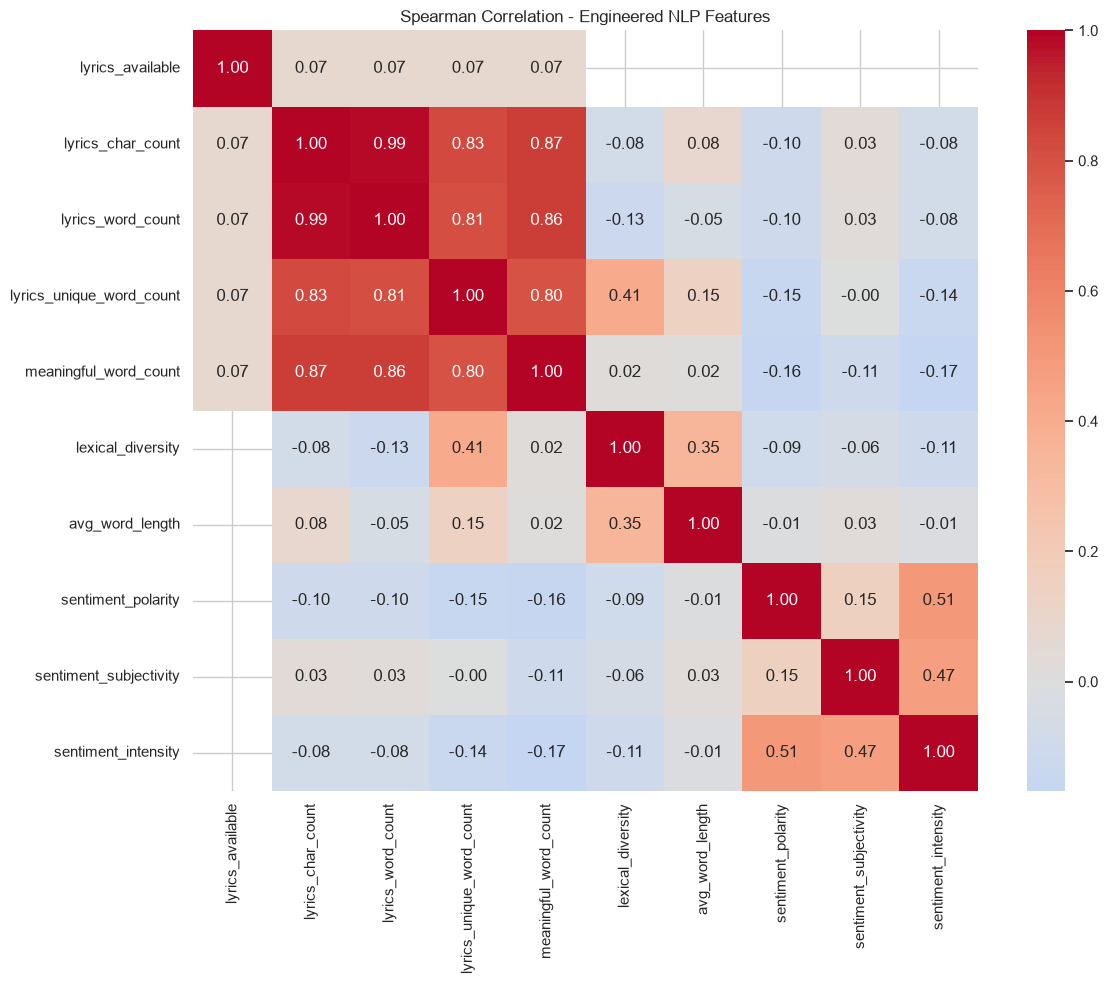

In [55]:
# 41. Feature Correlation Heatmap 

plt.figure(
    figsize=(12, 10)
)

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Spearman Correlation - Engineered NLP Features"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "engineered_feature_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

This helps identify highly correlated features

For example - lyrics_word_count & lyrics_char_count

are expected to be strongly correlated.

This doesn't mean one must always be removed, but it is something to consider for linear models.

Tree-based models generally handle correlated features more comfortably, although interpretation can still become difficult.

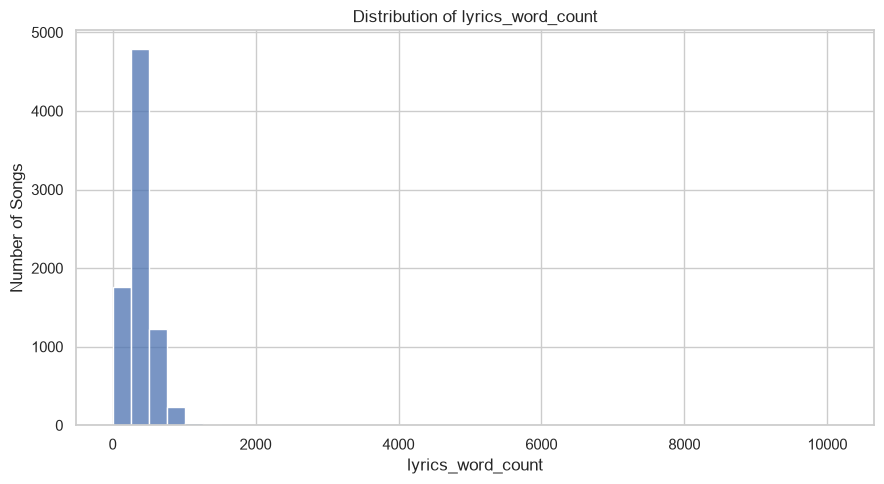

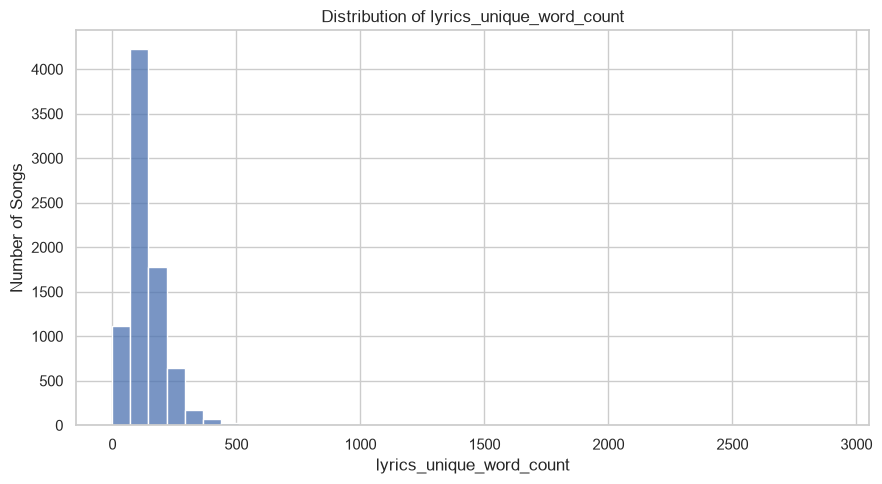

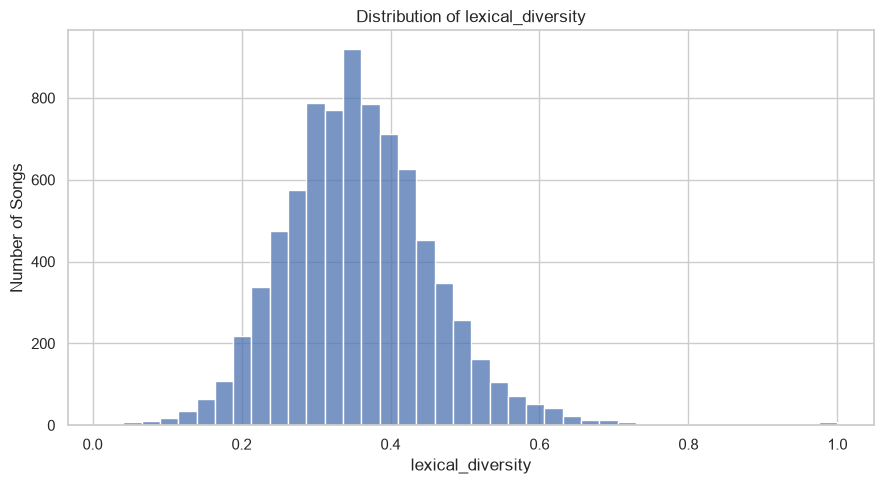

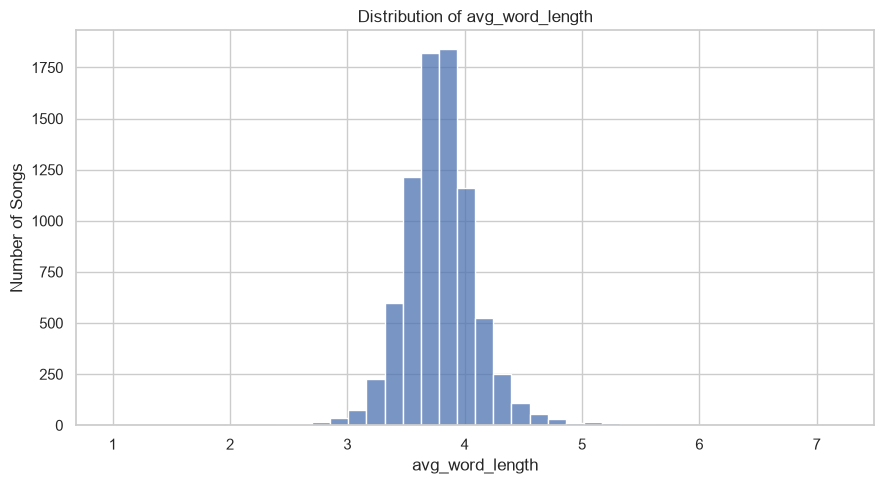

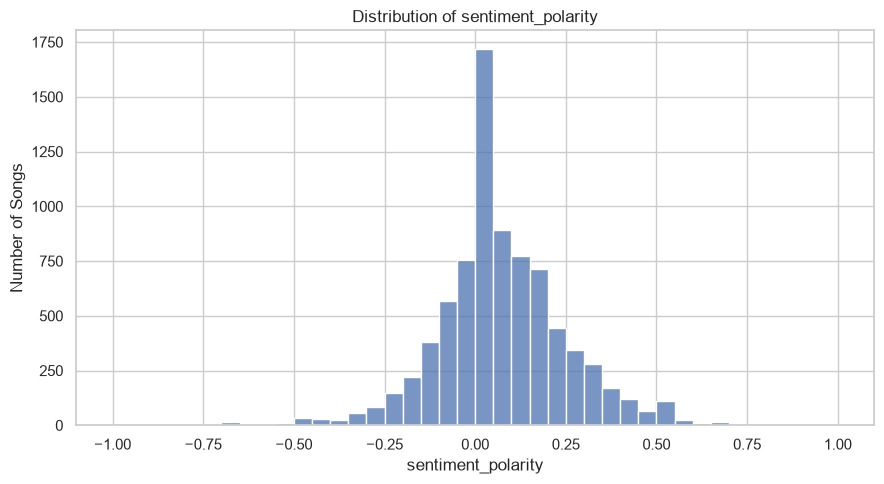

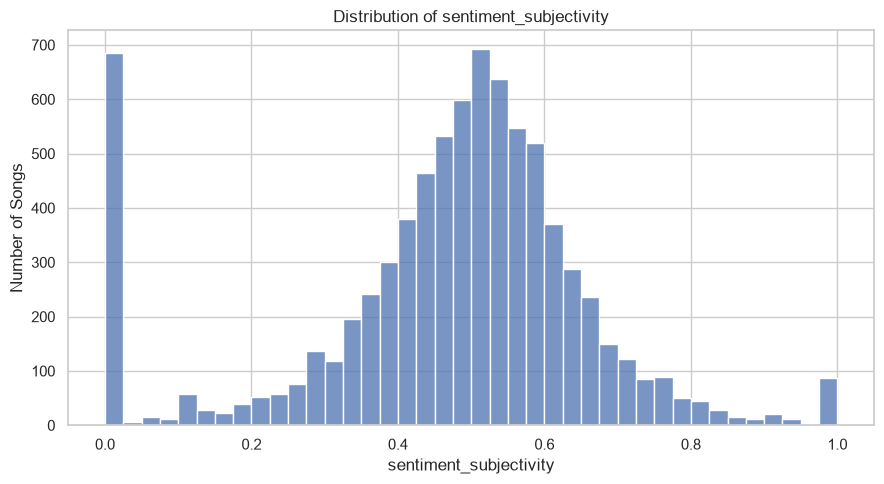

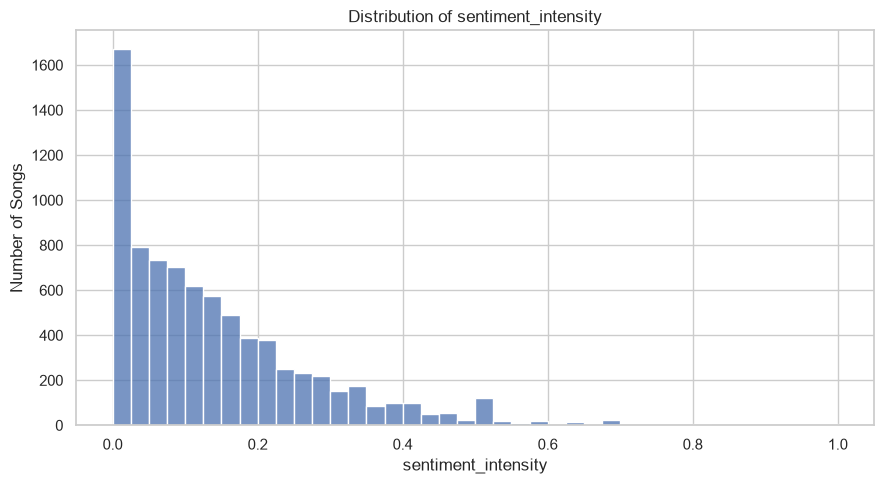

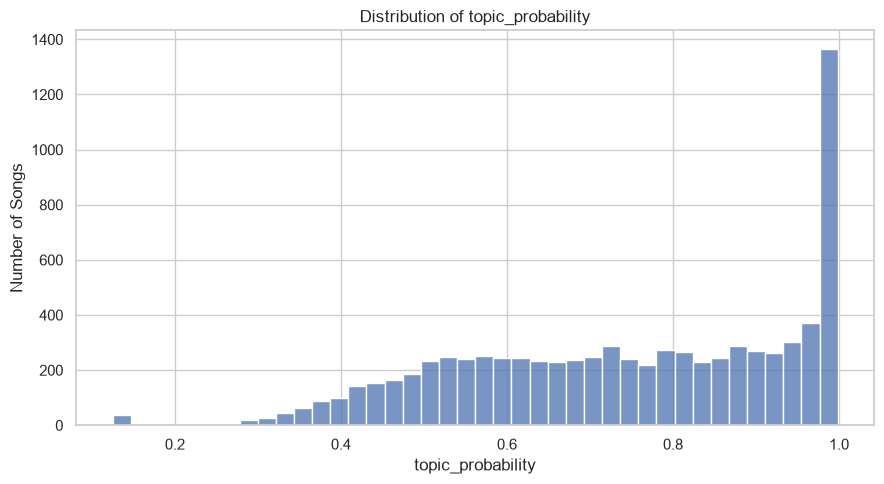

In [56]:
# 42. Distribution of Key Features

key_features = [
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "lexical_diversity",
    "avg_word_length",
    "sentiment_polarity",
    "sentiment_subjectivity",
    "sentiment_intensity",
    "topic_probability"
]

for col in key_features:

    plt.figure(
        figsize=(9, 5)
    )

    sns.histplot(
        data=feature_df,
        x=col,
        bins=40
    )

    plt.title(
        f"Distribution of {col}"
    )

    plt.xlabel(col)
    plt.ylabel("Number of Songs")

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR /
        f"{col}_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

### 43. Create Log NLP Features - Some NLP variables can also be skewed.

For example: 
lyrics_word_count, lyrics_char_count & meaningful_word_count

We can create log versions.

In [57]:
LOG_NLP_COLUMNS = [
    "lyrics_char_count",
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "meaningful_word_count"
]

for col in LOG_NLP_COLUMNS:

    feature_df[
        f"log_{col}"
    ] = np.log1p(
        feature_df[col]
    )

We retain both:
original feature & log-transformed feature.

because different algorithms may benefit from different representations.

We will decide which to use during model comaprison.

In [ ]:
# 44. Create Final Feature Groups 
# This is important for keeping the project organozed.

FEATURE_GROUPS = {

    "lyrics_length" : [
        "lyrics_char_count",
        "lyrics_word_count",
        "lyrics_unique_word_count",
        "meaningful_word_count "
    ],

    "lyrics_diversity": [
        "lexical_diversity",
        "avg_word_length",
        "lyric_repetition_ratio"
    ],

    "sentiment": [
        "sentiment_polarity",
        "sentiment_subjectivity",
        "sentiment_intensity"
    ],
    
}

for group, features in FEATURE_GROUPS.items():

    print(
        f"\n{group}:"
    )

    for feature in features:
        print(
            " -",
            feature
        )


lyrics_length:
 - lyrics_char_count
 - lyrics_word_count
 - lyrics_unique_word_count
 - meaningful_word_count 

lyrics_diversity:
 - lexical_diversity
 - avg_word_length
 - lyric_repetition_ratio

sentiment:
 - sentiment_polarity
 - sentiment_subjectivity
 - sentiment_intensity

topics:
 - dominant_topic
 - topic_probability


Instead of having one giant list, we know exactly where features come from

For example: Lyrics Length, Lyrics Diversity, Sentiment, Topics

This will also help later with SHAP interpretation.   

In [59]:
# check the exact column name

print([
    repr(col)
    for col in feature_df.columns
    if "meaningful" in col.lower()
])

["'meaningful_word_count'", "'log_meaningful_word_count'"]


In [60]:
# Recreate the engineered lyric features

# CREATE MISSING ENGINEERED FEATURES

# Remove accidental whitespace from column names
feature_df.columns = feature_df.columns.str.strip()

# Lyric repetition ratio
feature_df["lyric_repetition_ratio"] = (
    1 - feature_df["lexical_diversity"]
)

# Sentiment intensity
feature_df["sentiment_intensity"] = (
    feature_df["sentiment_polarity"].abs()
)

# Sentiment direction
feature_df["sentiment_direction"] = np.select(
    [
        feature_df["sentiment_polarity"] > 0.05,
        feature_df["sentiment_polarity"] < -0.05
    ],
    [
        "Positive",
        "Negative"
    ],
    default="Neutral"
)

print("Engineered lyric features created")


Engineered lyric features created


In [ ]:
# Recreate FINAL_MODEL_FEATURES

FEATURE_GROUPS = {
    "lyrics_length": [
        "lyrics_char_count",
        "lyrics_word_count",
        "lyrics_unique_word_count",
        "meaningful_word_count"
    ],

    "lyrics_diversity": [
        "lexical_diversity",
        "avg_word_length",
        "lyric_repetition_ratio"
    ],

    "sentiment": [
        "sentiment_polarity",
        "sentiment_subjectivity",
        "sentiment_intensity"
    ],
   
}

FINAL_MODEL_FEATURES = (
    FEATURE_GROUPS["lyrics_length"]
    + FEATURE_GROUPS["lyrics_diversity"]
    + FEATURE_GROUPS["sentiment"]
   
)

In [62]:
# Validate before displaying 

missing_features = [
    col 
    for col in FINAL_MODEL_FEATURES
    if col in feature_df.columns
]

print("Number of final model features:", len(FINAL_MODEL_FEATURES))
print("Missing Features:", missing_features)


Number of final model features: 12
Missing Features: ['lyrics_char_count', 'lyrics_word_count', 'lyrics_unique_word_count', 'meaningful_word_count', 'lexical_diversity', 'avg_word_length', 'lyric_repetition_ratio', 'sentiment_polarity', 'sentiment_subjectivity', 'sentiment_intensity', 'dominant_topic', 'topic_probability']


In [63]:
# 45. Create Final Modeling Feature Table

FINAL_MODEL_FEATURES = (
    FEATURE_GROUPS["lyrics_length"]
    + FEATURE_GROUPS["lyrics_diversity"]
    + FEATURE_GROUPS["sentiment"]
    + FEATURE_GROUPS["topics"]
)

print(
    "Total final NLP modeling features:",
    len(FINAL_MODEL_FEATURES)
)

display(
    feature_df[
        FINAL_MODEL_FEATURES
    ].head()
)

Total final NLP modeling features: 12


,lyrics_char_count,lyrics_word_count,lyrics_unique_word_count,meaningful_word_count,lexical_diversity,avg_word_length,lyric_repetition_ratio,sentiment_polarity,sentiment_subjectivity,sentiment_intensity,dominant_topic,topic_probability
0,1089,235,92,99,0.391489,3.638298,0.608511,0.037500,0.597222,0.037500,5,0.679882
1,2940,669,144,282,0.215247,3.396114,0.784753,0.299260,0.493270,0.299260,2,0.811826
2,1115,245,97,82,0.395918,3.555102,0.604082,0.078571,0.250595,0.078571,5,0.735412
3,1655,346,134,155,0.387283,3.786127,0.612717,-0.100366,0.656995,0.100366,5,0.763539
4,1543,323,95,132,0.294118,3.780186,0.705882,0.267677,0.541414,0.267677,5,0.991246


### 46. Create Final Modeling Dataset
we'll create a single dataset containing
song identifiers, NLP features, target variables & selected descriptive information

In [64]:
modeling_dataset = feature_df[
    [
        "artist name",
        "song name"
    ]
    + FINAL_MODEL_FEATURES
    + [
        "high_total_streams",
        "long_running_song",
        "top10_reached"
    ]
].copy()

print(
    "Modeling dataset shape:",
    modeling_dataset.shape
)

display(
    modeling_dataset.head()
)

Modeling dataset shape: (8058, 17)


,artist name,song name,lyrics_char_count,lyrics_word_count,lyrics_unique_word_count,meaningful_word_count,lexical_diversity,avg_word_length,lyric_repetition_ratio,sentiment_polarity,sentiment_subjectivity,sentiment_intensity,dominant_topic,topic_probability,high_total_streams,long_running_song,top10_reached
0,The Weeknd,Blinding Lights,1089,235,92,99,0.391489,3.638298,0.608511,0.037500,0.597222,0.037500,5,0.679882,1,1,1
1,Ed Sheeran,Shape of You,2940,669,144,282,0.215247,3.396114,0.784753,0.299260,0.493270,0.299260,2,0.811826,1,1,1
2,Harry Styles,As It Was,1115,245,97,82,0.395918,3.555102,0.604082,0.078571,0.250595,0.078571,5,0.735412,1,1,1
3,The Neighbourhood,Sweater Weather,1655,346,134,155,0.387283,3.786127,0.612717,-0.100366,0.656995,0.100366,5,0.763539,1,1,0
4,Lewis Capaldi,Someone You Loved,1543,323,95,132,0.294118,3.780186,0.705882,0.267677,0.541414,0.267677,5,0.991246,1,1,1


In [65]:
# 47. Save Modeling Dataset

MODELING_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_modeling_features.csv"
)

modeling_dataset.to_csv(
    MODELING_DATA_PATH,
    index=False 
)

print(
    "Modeling feature dataset saved:"   
)

print(
    MODELING_DATA_PATH
)

Modeling feature dataset saved:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_modeling_features.csv


In [66]:
# 48. Save High-Stream Dataset 

HIGH_STREAM_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_high_stream_modeling.csv"
)

high_stream_model_df = feature_df[
    [
        "artist name",
        "song name"
    ]
    + FINAL_MODEL_FEATURES
    + ["high_total_streams"]
].copy()

high_stream_model_df.to_csv(
    HIGH_STREAM_PATH,
    index=False 
)

print(
    HIGH_STREAM_PATH
)

C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_high_stream_modeling.csv


In [67]:
# 49. Save Longevity Dataset

LONGEVITY_MODEL_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_longevity_modeling.csv"
)

longevity_model_df = feature_df[
    [
        "artist name",
        "song name"
    ]
    + FINAL_MODEL_FEATURES
    + ["long_running_song"]
].copy()

longevity_model_df.to_csv(
    LONGEVITY_MODEL_PATH,
    index=False
)

print(
    LONGEVITY_MODEL_PATH
)


C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_longevity_modeling.csv


In [68]:
# 50. Save Top-10 Dataset

TOP10_MODEL_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_top10_modeling.csv"
)

top10_model_df = feature_df[
    [
        "artist name",
        "song name"
    ]
    + FINAL_MODEL_FEATURES
    + ["top10_reached"]
].copy()

top10_model_df.to_csv(
    TOP10_MODEL_PATH,
    index=False
)

print(
    TOP10_MODEL_PATH
)

C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_top10_modeling.csv


In [69]:
# 51. Create Feature Dictionary 

feature_dictionary = pd.DataFrame({

    "feature": [
        "lyrics_char_count",
        "lyrics_word_count",
        "lyrics_unique_word_count",
        "meaningful_word_count",
        "lexical_diversity",
        "avg_word_length",
        "lyric_repetition_ratio",
        "sentiment_polarity",
        "sentiment_subjectivity",
        "sentiment_intensity",
        "dominant_topic",
        "topic_probability"
    ],

    "category": [
        "Lyrics Length",
        "Lyrics Length",
        "Lyrics Diversity",
        "Lyrics Length",
        "Lyrics Diversity",
        "Lyrics Diversity",
        "Lyrics Diversity",
        "Sentiment",
        "Sentiment",
        "Sentiment",
        "Topic",
        "Topic"
    ],

    "description": [
        "Number of characters in cleaned lyrics",
        "Total number of words",
        "Number of unique words",
        "Number of words remaining after stopword removal",
        "Unique words divided by total words",
        "Average number of characters per word",
        "One minus lexical diversity",
        "TextBlob sentiment polarity",
        "TextBlob sentiment subjectivity",
        "Absolute sentiment polarity",
        "Dominant LDA topic",
        "Probability of dominant LDA topic"
    ]
})

display(
    feature_dictionary
)

,feature,category,description
0,lyrics_char_count,Lyrics Length,Number of characters in cleaned lyrics
1,lyrics_word_count,Lyrics Length,Total number of words
2,lyrics_unique_word_count,Lyrics Diversity,Number of unique words
3,meaningful_word_count,Lyrics Length,Number of words remaining after stopword removal
4,lexical_diversity,Lyrics Diversity,Unique words divided by total words
5,avg_word_length,Lyrics Diversity,Average number of characters per word
6,lyric_repetition_ratio,Lyrics Diversity,One minus lexical diversity
7,sentiment_polarity,Sentiment,TextBlob sentiment polarity
8,sentiment_subjectivity,Sentiment,TextBlob sentiment subjectivity
9,sentiment_intensity,Sentiment,Absolute sentiment polarity


In [70]:
# Save

feature_dictionary.to_csv(
    TABLE_DIR /
    "feature_dictionary.csv",
    index=False
)

In [71]:
# 52. Final Leakage Audit 

LEAKAGE_COLUMNS = [
    "total",
    "wks",
    "t10",
    "PkStreams",
    "pk",
    "top10_reached",
    "high_total_streams",   
    "long_running_song",
    "streams_per_week",
    "peak_streams_per_week",
    "top10_week_ratio",
    "peak_stream_share",
    "log_total",
    "log_wks",
    "log_PkStreams"
]

leakage_in_features = [
    col 
    for col in FINAL_MODEL_FEATURES
    if col in LEAKAGE_COLUMNS
]

print(
    "Potential leakage columns found in final features:"
)

print(
    leakage_in_features
)

Potential leakage columns found in final features:
[]


In [72]:
# 53. Target Distribution Check 

target_summary = pd.DataFrame({
    "target": [
        "high_total_streams",
        "long_running_song",
        "top10_reached"
    ],

    "positive_class_count": [
        feature_df[
            "high_total_streams"
        ].sum(),

        feature_df[
            "long_running_song"
        ].sum(),

        feature_df[
            "top10_reached"
        ].sum(),
        
    ],

    "positive_class_percentage": [
        feature_df[
            "high_total_streams"
        ].mean() * 100,

        feature_df[
            "long_running_song"
        ].mean() * 100,

        feature_df[
            "top10_reached"
        ].mean() * 100
    ]
})


display(
    target_summary
)

,target,positive_class_count,positive_class_percentage
0,high_total_streams,2015,25.006205
1,long_running_song,2051,25.452966
2,top10_reached,810,10.052122


This tells us whether the classification problem is balanced.

The Top-10 is likely to be more imbalanced.

In [73]:
# 54. Final Dataset Validation

validation = {

    "Correct row count":
    len(feature_df) == len(df),

    "No duplicate modeling rows":
    not modeling_dataset.duplicated(
        subset=[
            "artist name",
            "song name"
        ]
    ).all(),

    "NLP features present":
        all(
            col in feature_df.columns
            for col in FINAL_MODEL_FEATURES
        ),

    "High stream target present":
        "high total streams"
        in feature_df.columns,

    "Longevity target present":
        "long_running_song"
        in feature_df.columns,

    "Top10 target present":
        "top10_reached"
        in feature_df.columns,

    "No leakage features":
        len(leakage_in_features) == 0,

    "Modeling file exists":
        MODELING_DATA_PATH.exists(),

    "High stream file exists":
        HIGH_STREAM_PATH.exists(),

    "Longevity file exists":
        LONGEVITY_MODEL_PATH.exists(),

    "Top10 file exists":
        TOP10_MODEL_PATH.exists()
 }

display(
    pd.Series(
        validation,
        name="Validation"
    )
 )

print(
    "\nAll checks passed:",
    all(validation.values())
 )

Correct row count              True
No duplicate modeling rows     True
NLP features present           True
High stream target present    False
Longevity target present       True
Top10 target present           True
No leakage features            True
Modeling file exists           True
High stream file exists        True
Longevity file exists          True
Top10 file exists              True
Name: Validation, dtype: bool


All checks passed: False


The duplicate check above can be misleading because legitimate repeated artist-song records exist in the source data.

In [74]:
# Use the stronger check instead

print(
    "Modeling rows:",
    len(modeling_dataset)
)

print(
    "Expected rows:",
    len(feature_df)
)

print(
    "Duplicate complete modeling rows:",
    modeling_dataset.duplicated().sum()
)

Modeling rows: 8058
Expected rows: 8058
Duplicate complete modeling rows: 95


The important validation is that the number of rows remains 8,058

In [75]:
# 55. Save Complete Engineered Dataset

ENGINEERED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_feature_engineered.csv"
)

feature_df.to_csv(
    ENGINEERED_DATA_PATH,
    index=False 
)

print(
    "Complete engineered dataset saved:"
)

print(
    ENGINEERED_DATA_PATH
)

Complete engineered dataset saved:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_feature_engineered.csv


In [76]:
# 56. Final Output Summary 

print("=" * 70)
print("NOTEBOOK 07 OUTPUTS")
print("=" * 70)

print("\nProcessed datasets:")

for path in [
    NLP_DATA_PATH,
    MODELING_DATA_PATH,
    HIGH_STREAM_PATH,
    LONGEVITY_MODEL_PATH,
    TOP10_MODEL_PATH,
    ENGINEERED_DATA_PATH
]:
    print(
        "✓",
        path.name
    )


print("\nOutput tables:")

for path in sorted(
    TABLE_DIR.glob("*")
):

    print(
        "✓",
        path.name 
    )

print("\nOutput figures:")


for path in sorted(
    OUTPUT_DIR.glob("*")
):

    print(
        "✓",
        path.name
    )

NOTEBOOK 07 OUTPUTS

Processed datasets:
✓ spotify_lyrics_nlp_features.csv
✓ spotify_modeling_features.csv
✓ spotify_high_stream_modeling.csv
✓ spotify_longevity_modeling.csv
✓ spotify_top10_modeling.csv
✓ spotify_feature_engineered.csv

Output tables:
✓ feature_dictionary.csv
✓ modeling_feature_summary.csv

Output figures:
✓ avg_word_length_distribution.png
✓ engineered_feature_correlation.png
✓ lexical_diversity_distribution.png
✓ lyrics_unique_word_count_distribution.png
✓ lyrics_word_count_distribution.png
✓ sentiment_intensity_distribution.png
✓ sentiment_polarity_distribution.png
✓ sentiment_subjectivity_distribution.png
✓ topic_probability_distribution.png


### Final Notebook Conclusion

### Feature Engineering

The cleaned Spotify chart dataset and the lyrics NLP dataset were successfully combined at the song-record level.

The resulting feature set includes four major groups:

### 1. Lyrics Length 

- Character count
- Word count
- Unique word count
- Meaningful word count

### 2. Lyrics Diversity

- Lexical diversity
- Average word length
- Lyric repetition ratio

### 3. Sentiment

- Sentiment polarity
- Sentiment subjectivity
- Sentiment intensity

### 4. Topics

- Dominant topic
- Topic probability

### Prediction Targets

Three possible classification targets were created:

### High Total Streams

Song in the top 25% of lifetime total streams.

### Long-Running Song

Songs in the top 25% of chart longevity

### Top-10 Reached 

Songs that reached the Top-10.

### Leakage prevention

Lifetime chart-performance variables such as:

- total streams
- weeks on chart
- Top-10 weeks
- peak streams
- peak position

are treated as outcomes rather than predictors in the initial content-based modeling framework.

This prevents the model from using information that would only become known after the song had already accumulated its chart history.

### Modeling Outputs

The following datasets were created:

- spotify_modeling_features.csv
- spotify_high_stream_modeling.csv
- spotify_longevity_modeling.csv
- spotify_top10_modeling.csv

These datasets are ready for the next stage of the project.

### Next Step

Notebook 08 will use the engineered features and performance characteristics to identify different types of songs through unsupervised segmentation.


